In [1]:
import os
import re
import cv2
import wandb
import shutil
import kagglehub
import ipynbname
import pytesseract
import pandas as pd
from glob import glob
from ultralytics import YOLO
from dotenv import load_dotenv
import matplotlib.pyplot as plt
import xml.etree.ElementTree as xet
from wandb.integration.ultralytics import add_wandb_callback
from sklearn.model_selection import train_test_split
import torch

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

wandb: WARNING This integration is tested and supported for ultralytics v8.0.238 and below.
wandb: WARNING         Please report any issues to https://github.com/wandb/wandb/issues with the tag `yolov8`.


'cpu'

In [2]:
load_dotenv(dotenv_path='.env.experimental')

wandb_key = os.getenv('WANDB_API_KEY')
wandb_entity = os.getenv('WANDB_ENTITY')

wandb.login(key=wandb_key)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.forge.coreweave.com.
wandb: Appending key for api.forge.coreweave.com to your netrc file: C:\Users\Pasidu\_netrc
wandb: Currently logged in as: psewmuthu (PS-Private) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


True

In [3]:
dataset_path = kagglehub.dataset_download("andrewmvd/car-plate-detection")

100%|██████████| 203M/203M [12:09<00:00, 292kB/s] 

Extracting files...


In [4]:
def the_number_in_the_string(filename):
    # Search for the first occurrence of one or more digits in the filename
    match = re.search(r'(\d+)', filename)
    
    # If a match is found, return the matched number as an integer
    if match:
        return int(match.group(0))
    # If no match is found, return 0
    else:
        return 0

print(the_number_in_the_string("file123.txt"))
print(the_number_in_the_string("no_numbers_here"))

123
0


In [5]:
# Initialize a dictionary to store labels and image information
labels_dict = dict(
    img_path=[], 
    xmin=[], 
    xmax=[], 
    ymin=[], 
    ymax=[], 
    img_w=[], 
    img_h=[]
)

# Get the list of XML files from the annotations directory
xml_files = glob(f'{dataset_path}/annotations/*.xml')

# Process each XML file, sorted by the numerical value in the filename
for filename in sorted(xml_files, key=the_number_in_the_string):
    # Parse the XML file
    info = xet.parse(filename)
    root = info.getroot()
    
    # Find the 'object' element in the XML and extract bounding box information
    member_object = root.find('object')
    labels_info = member_object.find('bndbox')
    xmin = int(labels_info.find('xmin').text)
    xmax = int(labels_info.find('xmax').text)
    ymin = int(labels_info.find('ymin').text)
    ymax = int(labels_info.find('ymax').text)
    
    # Get the image filename and construct the full path to the image
    img_name = root.find('filename').text
    img_path = os.path.join(dataset_path, 'images', img_name)

    # Append the extracted information to the respective lists in the dictionary
    labels_dict['img_path'].append(img_path)
    labels_dict['xmin'].append(xmin)
    labels_dict['xmax'].append(xmax)
    labels_dict['ymin'].append(ymin)
    labels_dict['ymax'].append(ymax)
    
    # Read the image to get its dimensions
    height, width, _ = cv2.imread(img_path).shape
    labels_dict['img_w'].append(width)
    labels_dict['img_h'].append(height)
    
# Convert the dictionary to a pandas DataFrame
alldata = pd.DataFrame(labels_dict)

alldata

,img_path,xmin,xmax,ymin,ymax,img_w,img_h
0,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,226,419,125,173,500,268
1,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,134,262,128,160,400,248
2,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,140,303,5,148,400,225
3,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,175,214,114,131,400,267
4,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,167,240,202,220,400,300
...,...,...,...,...,...,...,...
428,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,278,407,182,263,600,400
429,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,133,261,126,160,400,248
430,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,98,297,102,191,400,300
431,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,85,247,196,259,370,400


In [6]:
# Split the data into training and test sets
# Use 10% of the data for the test set
train, test = train_test_split(alldata, test_size=1/10, random_state=42)

# Split the training data further into training and validation sets
# Use 8/9 of the remaining data for the training set, resulting in an 80/10/10 split overall
train, val = train_test_split(train, train_size=8/9, random_state=42)

# Print the number of samples in each set
print(f'''
      len(train) = {len(train)}
      len(val) = {len(val)}
      len(test) = {len(test)}
''')


      len(train) = 345
      len(val) = 44
      len(test) = 44



In [7]:
# Remove the 'datasets' directory if it exists
if os.path.exists('datasets'):
    shutil.rmtree('datasets')

In [8]:
train

,img_path,xmin,xmax,ymin,ymax,img_w,img_h
124,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,191,255,165,192,400,301
315,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,149,285,206,240,400,300
282,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,201,217,185,195,300,400
236,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,241,348,369,417,600,531
112,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,229,270,176,193,400,400
...,...,...,...,...,...,...,...
110,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,166,273,225,246,442,333
255,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,156,248,149,170,400,233
292,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,148,305,113,178,400,300
54,C:\Users\Pasidu\.cache\kagglehub\datasets\andr...,226,420,125,169,500,268


In [9]:
def make_split_folder_in_yolo_format(split_name, split_df):
  
    labels_path = os.path.join('datasets', 'cars_license_plate_new', split_name, 'labels')
    images_path = os.path.join('datasets', 'cars_license_plate_new', split_name, 'images')

    # Create directories for labels and images
    os.makedirs(labels_path)
    os.makedirs(images_path)
    
    # Iterate over each row in the DataFrame
    for _, row in split_df.iterrows():
        img_name, img_extension = os.path.splitext(os.path.basename(row['img_path']))
        
        # Calculate YOLO format bounding box coordinates
        x_center = (row['xmin'] + row['xmax']) / 2 / row['img_w']
        y_center = (row['ymin'] + row['ymax']) / 2 / row['img_h']
        width = (row['xmax'] - row['xmin']) / row['img_w']
        height = (row['ymax'] - row['ymin']) / row['img_h']

        # Save the label in YOLO format
        label_path = os.path.join(labels_path, f'{img_name}.txt')
        with open(label_path, 'w') as file:
            file.write(f"0 {x_center:.4f} {y_center:.4f} {width:.4f} {height:.4f}\n")
            
        # Copy the image to the images directory
        shutil.copy(row['img_path'], os.path.join(images_path, img_name + img_extension))
    
    print(f"Created '{images_path}' and '{labels_path}'")

In [10]:
# Create YOLO format folders for train, validation, and test splits

make_split_folder_in_yolo_format("train", train)
make_split_folder_in_yolo_format("val", val)
make_split_folder_in_yolo_format("test", test)

Created 'datasets\cars_license_plate_new\train\images' and 'datasets\cars_license_plate_new\train\labels'
Created 'datasets\cars_license_plate_new\val\images' and 'datasets\cars_license_plate_new\val\labels'
Created 'datasets\cars_license_plate_new\test\images' and 'datasets\cars_license_plate_new\test\labels'


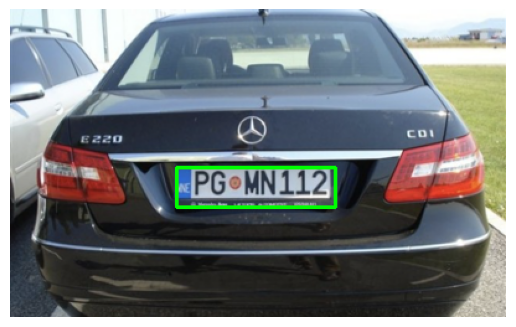

In [11]:
# Directory paths
image_dir = 'datasets/cars_license_plate_new/train/images'
label_dir = 'datasets/cars_license_plate_new/train/labels'

# Get the first image file
image_files = sorted(os.listdir(image_dir))
first_image_file = image_files[0]

# Construct paths for the image and its corresponding label
image_path = os.path.join(image_dir, first_image_file)
label_path = os.path.join(label_dir, os.path.splitext(first_image_file)[0] + '.txt')

# Load the image using OpenCV
image = cv2.imread(image_path)
# Convert the image from BGR (OpenCV default) to RGB (matplotlib default)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Read the label file to get bounding box information
with open(label_path, 'r') as f:
    lines = f.readlines()

# Plot the bounding box on the image
for line in lines:
    # Parse the label file line to extract bounding box information
    class_id, x_center, y_center, width, height = map(float, line.strip().split())
    img_height, img_width, _ = image.shape

    # Convert YOLO format to bounding box format
    x_center *= img_width
    y_center *= img_height
    width *= img_width
    height *= img_height

    # Calculate the top-left and bottom-right coordinates of the bounding box
    x1 = int(x_center - width / 2)
    y1 = int(y_center - height / 2)
    x2 = int(x_center + width / 2)
    y2 = int(y_center + height / 2)

    # Draw the bounding box on the image using a green rectangle
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)

# Display the image with bounding box using matplotlib
plt.imshow(image)
plt.axis('off')  # Hide the axis
plt.show()  # Display the image

In [12]:
nb_path = ipynbname.path()
nb_dir = nb_path.parent
path_to_datasets = os.path.join(nb_dir, 'datasets', 'cars_license_plate_new')

# Define the content of the datasets.yaml file
datasets_yaml = f'''
path: {path_to_datasets}

train: train/images
val: val/images
test: test/images

# number of classes
nc: 1

# class names
names: ['license_plate']
'''

# Write the content to the datasets.yaml file
with open('datasets.yaml', 'w') as file:
    file.write(datasets_yaml)

In [13]:
wandb.init(
    entity=wandb_entity,
    project='number-plate-detection',
    name='run-1',
    job_type='train'
)

In [14]:
model = YOLO('yolo12n.pt')

In [15]:
model.train(
    project='number-plate-detection',
    data='datasets.yaml',  # Path to the dataset configuration file
    epochs=50,            # Number of training epochs
    batch=16,              # Batch size
    device=device,         # Use CPU/GPU for training
    imgsz=320,             # Image size (width and height) for training
    cache=True             # Cache images for faster training
)

New https://pypi.org/project/ultralytics/8.4.204 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.203  Python-3.11.9 torch-2.15.0+cpu CPU (13th Gen Intel Core i5-1340P)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=True, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=datasets.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12n.pt, momentum=0.937, mosa

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x0000018F1B868F10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

In [16]:
wandb.finish()

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


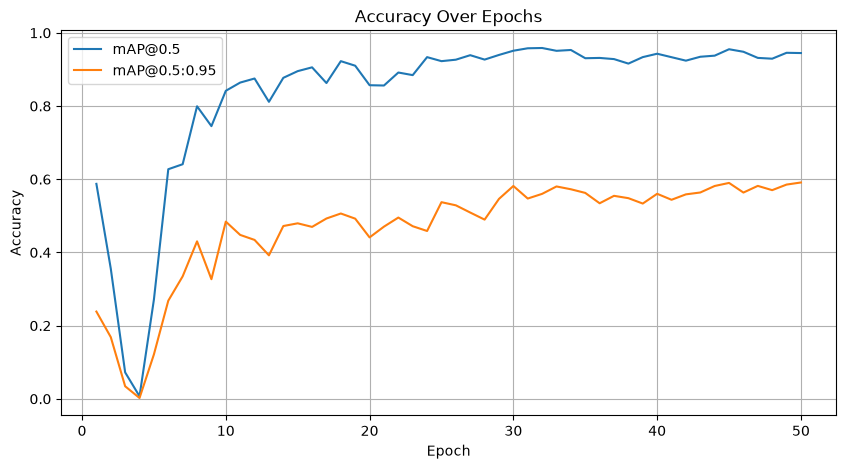

In [17]:
# Find the most recent training log directory
log_dir = max(glob('runs/detect/number-plate-detection/train*'), key=the_number_in_the_string)

# Load the training results from the CSV file
results = pd.read_csv(os.path.join(log_dir, 'results.csv'))
results.columns = results.columns.str.strip()  # Remove any leading/trailing whitespace from column names

# Extract epochs and accuracy metrics
epochs = results.index + 1  # Epochs are zero-indexed, so add 1
mAP_0_5 = results['metrics/mAP50(B)']  # Mean Average Precision at IoU=0.5
mAP_0_5_0_95 = results['metrics/mAP50-95(B)']  # Mean Average Precision at IoU=0.5:0.95

# Plot the accuracy over epochs
plt.figure(figsize=(10, 5))
plt.plot(epochs, mAP_0_5, label='mAP@0.5')
plt.plot(epochs, mAP_0_5_0_95, label='mAP@0.5:0.95')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Accuracy Over Epochs')
plt.legend()
plt.grid(True)
plt.show()

In [18]:
# Save the trained model
model_path = '../models'
os.makedirs(model_path, exist_ok=True)

model.save(f'{model_path}/license_plate_model.pt')

In [19]:
def predict_and_plot(path_test_car):
    """
    Predicts and plots the bounding boxes on the given test image using the trained YOLO model.

    Parameters:
    path_test_car (str): Path to the test image file.
    """
    # Perform prediction on the test image using the model
    results = model.predict(path_test_car, device='cpu')

    # Load the image using OpenCV
    image = cv2.imread(path_test_car)
    # Convert the image from BGR (OpenCV default) to RGB (matplotlib default)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Extract the bounding boxes and labels from the results
    for result in results:
        for box in result.boxes:
            # Get the coordinates of the bounding box
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            # Get the confidence score of the prediction
            confidence = box.conf[0]

            # Draw the bounding box on the image
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
            # Draw the confidence score near the bounding box
            cv2.putText(image, f'{confidence*100:.2f}%', (x1, y1 - 10), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

    # Plot the image with bounding boxes
    plt.imshow(image)
    plt.axis('off')  # Hide the axis
    plt.show()  # Display the image


image 1/1 C:\Users\Pasidu\.cache\kagglehub\datasets\andrewmvd\car-plate-detection\versions\1\images\Cars235.png: 192x320 1 license_plate, 68.0ms
Speed: 2.3ms preprocess, 68.0ms inference, 1.5ms postprocess per image at shape (1, 3, 192, 320)


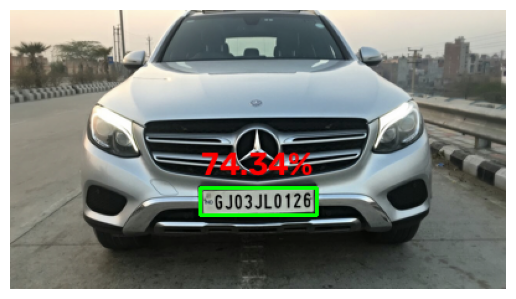

In [20]:
predict_and_plot(test.iloc[10].img_path)


image 1/1 C:\Users\Pasidu\.cache\kagglehub\datasets\andrewmvd\car-plate-detection\versions\1\images\Cars277.png: 256x320 2 license_plates, 157.7ms
Speed: 2.5ms preprocess, 157.7ms inference, 0.8ms postprocess per image at shape (1, 3, 256, 320)


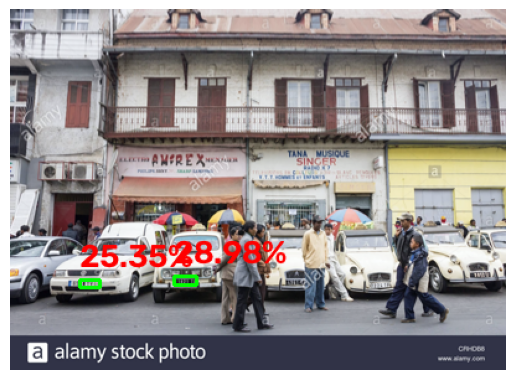

In [21]:
predict_and_plot(test.iloc[25].img_path)


image 1/1 C:\Users\Pasidu\.cache\kagglehub\datasets\andrewmvd\car-plate-detection\versions\1\images\Cars65.png: 288x320 1 license_plate, 128.9ms
Speed: 1.0ms preprocess, 128.9ms inference, 0.6ms postprocess per image at shape (1, 3, 288, 320)


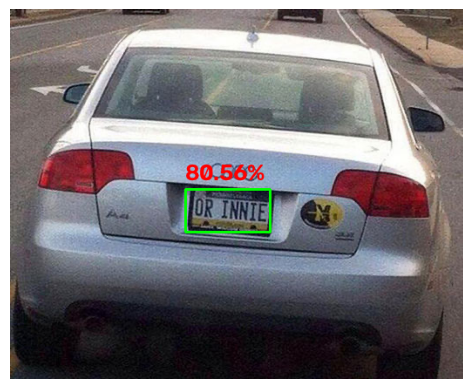

In [22]:
predict_and_plot(test.iloc[15].img_path)

In [25]:
# Add this line and point it to your tesseract.exe path
pytesseract.pytesseract.tesseract_cmd = r'C:\Program Files\Tesseract-OCR\tesseract.exe'

In [26]:
def predict_and_plot(path_test_car):
    """
    Predicts and plots the bounding boxes on the given test image using the trained YOLO model.
    Also performs OCR on the detected bounding boxes to extract text.
    
    Parameters:
    path_test_car (str): Path to the test image file.
    """
    # Perform prediction on the test image using the model
    results = model.predict(path_test_car, device='cpu')

    # Load the image using OpenCV
    image = cv2.imread(path_test_car)
    # Convert the image from BGR (OpenCV default) to RGB (matplotlib default)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Extract the bounding boxes and labels from the results
    for result in results:
        for box in result.boxes:
            # Get the coordinates of the bounding box
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            # Get the confidence score of the prediction
            confidence = box.conf[0]

            # Draw the bounding box on the image
            cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
            # Draw the confidence score near the bounding box
            cv2.putText(image, f'{confidence*100:.2f}%', (x1, y1 - 10), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

            # Crop the bounding box from the image for OCR
            roi = image[y1:y2, x1:x2]

            # Perform OCR on the cropped image
            text = pytesseract.image_to_string(roi, config='--psm 6')
            print(f"Detected text: {text}")

    # Plot the image with bounding boxes
    plt.imshow(image)
    plt.axis('off')  # Hide the axis
    plt.show()  # Display the image


image 1/1 C:\Users\Pasidu\.cache\kagglehub\datasets\andrewmvd\car-plate-detection\versions\1\images\Cars133.png: 224x320 1 license_plate, 103.0ms
Speed: 1.5ms preprocess, 103.0ms inference, 2.4ms postprocess per image at shape (1, 3, 224, 320)
Detected text: 


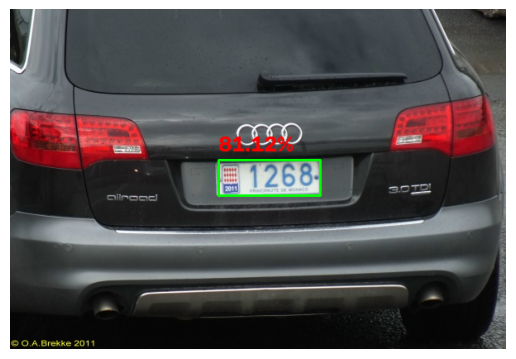

In [27]:
predict_and_plot(test.iloc[14].img_path)


image 1/1 C:\Users\Pasidu\.cache\kagglehub\datasets\andrewmvd\car-plate-detection\versions\1\images\Cars426.png: 256x320 1 license_plate, 105.3ms
Speed: 1.9ms preprocess, 105.3ms inference, 3.7ms postprocess per image at shape (1, 3, 256, 320)
Detected text: CRAIG.



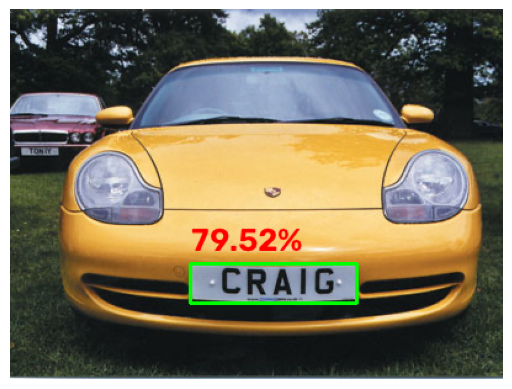

In [28]:
predict_and_plot(test.iloc[4].img_path)


image 1/1 C:\Users\Pasidu\.cache\kagglehub\datasets\andrewmvd\car-plate-detection\versions\1\images\Cars238.png: 224x320 1 license_plate, 75.2ms
Speed: 1.4ms preprocess, 75.2ms inference, 2.5ms postprocess per image at shape (1, 3, 224, 320)
Detected text: iad DO



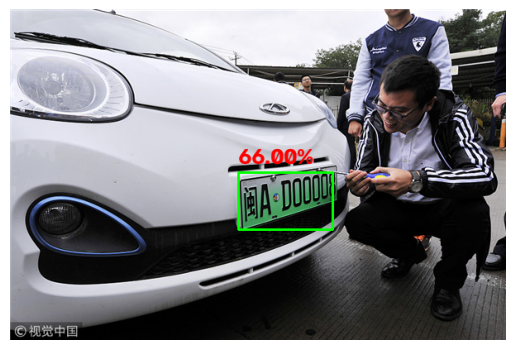

In [29]:
predict_and_plot(test.iloc[7].img_path)